# 로더와 스플리터

**이 노트북에서 할 일**

1. 직접 만든 로더 함수로 도서관 안내 PDF(E01) 5쪽을 Document 목록으로 읽습니다.
2. 스플리터가 줄을 모아 문서 청크를 만드는 규칙과 겹침, 글자 수와 토큰 수를 출력으로 봅니다.
3. 겹침이 한 줄보다 짧아 휴관 조건이 갈라지는 Before와, 겹침을 늘린 After를 비교합니다.

**준비물** — 데이터 파일은 `labs/data/rag-corpus/pdf/easy/E01.pdf`입니다.
이 노트북은 모델에 요청을 보내지 않으므로 API 키가 없어도 실행됩니다. 요금도 들지 않습니다.
라이브러리 tiktoken은 처음 실행할 때 토큰화 규칙 파일 두 개를 인터넷에서 내려받습니다. 실행 시간은 30초 안팎입니다.

**강의와 실습 범위** — 강의 시간에는 2~4절(로더, 스플리터 규칙과 겹침, 글자 수와 토큰 수)을 설명합니다.
5절 값 바꿔 보기와 Before·After는 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 판을 씁니다. pypdf 6.17.0, langchain-core 1.6.2입니다.
함께 쓰는 판은 langchain-text-splitters 1.1.2와 tiktoken 0.14.0입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch09-rag-first-run`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위 칸 로더에는 초록 상자 E01.pdf 5쪽, 파란 상자 load_pdf_pages 쪽마다 extract_text, 초록 상자 Document 5개 본문 str 메타데이터 dict가 왼쪽에서 오른쪽으로 있고, 아래 칸 스플리터에는 파란 상자 RecursiveCharacterTextSplitter 500자 겹침 50자, 초록 상자 문서 청크 8개 메타데이터 복사가 있으며, 맨 아래 회색 상자 03절 임베딩은 이 절에서 실행하지 않음이 점선 화살표로 이어진 흐름도](attachment:02-1-로더와-스플리터.png)

위 칸은 PDF를 쪽마다 읽어 Document로 만드는 로더, 아래 칸은 Document를 문서 청크로 나누는 스플리터입니다.
초록 상자는 코드가 만든 자료, 파란 상자는 코드 단계입니다. 회색 상자는 이 절에서 실행하지 않는 다음 단계입니다.
노트북 2절이 위 칸, 3~5절이 아래 칸을 실행합니다.
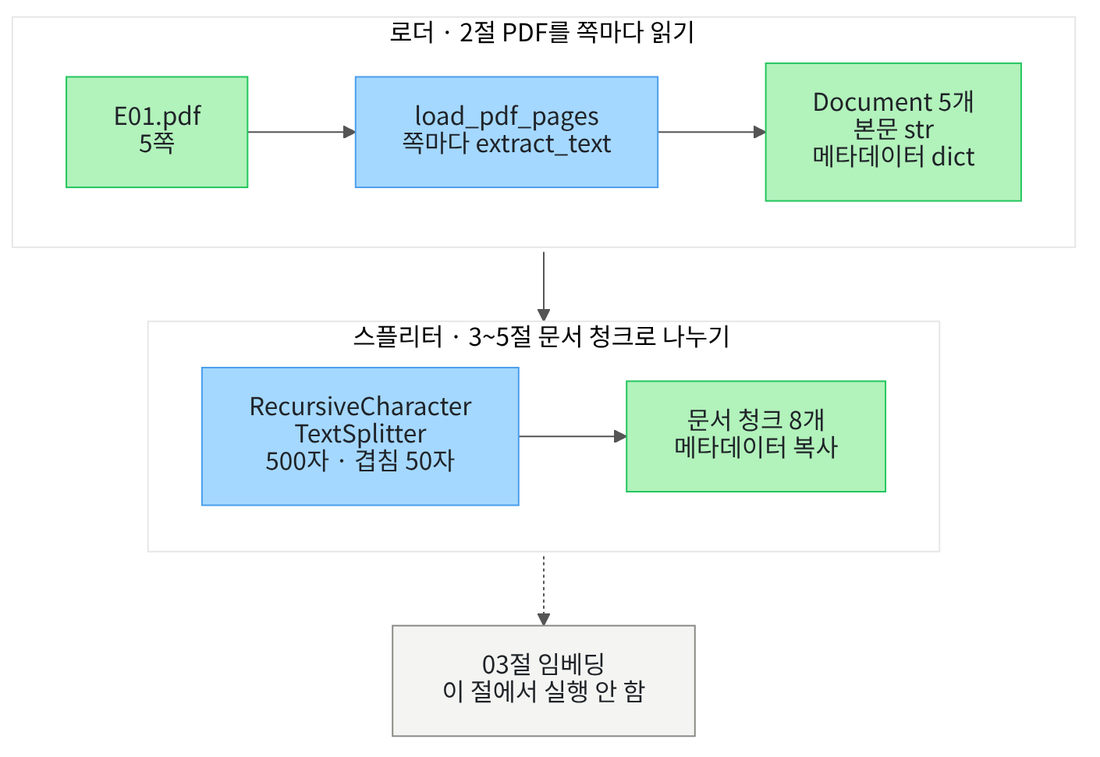

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01절과 달리 임베딩·벡터스토어·모델은 쓰지 않고, 토큰을 세는 tiktoken을 씁니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.17.0" "langchain==1.4.0" "langchain-text-splitters==1.1.2" "tiktoken==0.14.0"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))
print("langchain-text-splitters:", version("langchain-text-splitters"))
print("tiktoken:", version("tiktoken"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.17.0
langchain-core: 1.6.2
langchain-text-splitters: 1.1.2
tiktoken: 0.14.0


**결과 읽기** — 출력 줄은 `pypdf: 6.17.0`, `langchain-core: 1.6.2`, `langchain-text-splitters: 1.1.2`, `tiktoken: 0.14.0`입니다.
준비물에 적은 기준 버전과 같습니다. 이 노트북의 출력은 2026-09-17에 실행한 결과입니다.

PDF 읽기, 문서 객체, 글 나누기, 토큰 세기에 쓸 이름을 불러옵니다.
이름마다 처음 쓰는 절에서 무엇을 넣고 무엇을 반환하는지 설명합니다.

In [2]:
# PDF 읽기·Document·문서 청크 나누기·토큰 세기에 쓸 이름을 불러옵니다
import os

from pypdf import PdfReader
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
import tiktoken

## 2. 로더 함수로 PDF 5쪽 읽기

먼저 01절과 같은 셀로 PDF 경로를 고릅니다. 후보 경로를 차례로 확인하고, 있는 경로에서 멈춥니다.
실행 전에 예상합니다. 01절과 같은 폴더에서 열었다면 같은 후보를 고를 것입니다.

In [3]:
# 작업 폴더에서 본 E01.pdf 경로를 후보 세 개 가운데에서 고릅니다
candidates = [
    "labs/data/rag-corpus/pdf/easy/E01.pdf",
    "../../data/rag-corpus/pdf/easy/E01.pdf",
    "../../../data/rag-corpus/pdf/easy/E01.pdf",
]
pdf_path = None
for candidate in candidates:
    if os.path.exists(candidate):
        pdf_path = candidate
        break
print("PDF를 찾았는가:", pdf_path is not None)
print("고른 경로:", pdf_path)
assert pdf_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

PDF를 찾았는가: True
고른 경로: labs/data/rag-corpus/pdf/easy/E01.pdf


**결과 읽기** — 출력 줄은 `PDF를 찾았는가: True`와 `고른 경로: labs/data/rag-corpus/pdf/easy/E01.pdf`입니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.
`notebooks` 폴더에서 열면 셋째 후보가 나옵니다.

로더(loader)는 파일을 읽어 Document 목록으로 바꾸는 도구입니다. 두꺼운 안내 책자를 쪽마다 펼쳐 한 장씩 옮겨 적는 일과 비슷합니다.
01절 2절에서는 쪽마다 Document를 만드는 코드를 셀에 바로 적었습니다. 이번에는 그 코드를 함수 하나로 묶어 로더로 씁니다.

함수 `load_pdf_pages()`는 PDF 경로와 문서 이름을 받아, 쪽마다 Document를 담은 목록을 반환합니다.
메타데이터 `source`에는 문서 이름 뒤에 `.pdf`를 붙인 파일 이름을 적습니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [4]:
# PDF 경로와 문서 이름을 받아, 쪽마다 본문과 메타데이터를 담은 Document 목록을 반환하는 로더 함수를 정의합니다
def load_pdf_pages(pdf_path, doc_id):
    reader = PdfReader(pdf_path)
    page_documents = []
    page_number = 1
    for page in reader.pages:
        metadata = {"doc_id": doc_id, "page": page_number, "source": doc_id + ".pdf"}
        page_document = Document(page_content=page.extract_text(), metadata=metadata)
        page_documents.append(page_document)
        page_number = page_number + 1
    return page_documents

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

로더 함수로 E01.pdf를 읽습니다. 본문 `page_content`와 메타데이터 `metadata`가 어떤 자료형인지도 봅니다.
함수 `type()`은 Ch 2 01절에서 배운 대로 값의 자료형을 반환합니다.
실행 전에 예상합니다. 본문은 글(문자열), 메타데이터는 딕셔너리일 것입니다.

In [5]:
# 로더 함수로 E01.pdf를 읽고, Document 수와 2쪽 메타데이터, 본문·메타데이터의 자료형을 봅니다
pages = load_pdf_pages(pdf_path, "E01")
print("Document 수:", len(pages))
print("2쪽 메타데이터:", pages[1].metadata)
print("본문 자료형:", type(pages[1].page_content))
print("메타데이터 자료형:", type(pages[1].metadata))

Document 수: 5
2쪽 메타데이터: {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}
본문 자료형: <class 'str'>
메타데이터 자료형: <class 'dict'>


**결과 읽기** — 출력 줄은 `Document 수: 5`와 `2쪽 메타데이터: {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}`입니다.
자료형 두 줄은 `본문 자료형: <class 'str'>`과 `메타데이터 자료형: <class 'dict'>`입니다.

01절에서 셀로 만든 Document와 같은 값입니다. 로더를 함수로 묶어도 결과는 달라지지 않았습니다.

스플리터로 나누기 전에 쪽 글의 모양을 봅니다. 쪽마다 글자 수, 줄 수, 빈 줄이 있는지, 마지막 줄을 출력합니다.
빈 줄은 줄바꿈 글자 `\n`이 두 번 이어진 자리입니다. 3절에서 스플리터가 끊을 자리를 고를 때 이 값을 씁니다.

In [6]:
# 쪽마다 글자 수, 줄 수, 빈 줄(줄바꿈 두 번)이 있는지, 마지막 줄을 출력합니다
print("쪽 글(쪽 | 글자 수 | 줄 수 | 빈 줄이 있는가 | 마지막 줄):")
for page_document in pages:
    page_text = page_document.page_content
    lines = page_text.split("\n")
    has_blank_line = "\n\n" in page_text
    print(page_document.metadata["page"], "|", len(page_text), "|", len(lines), "|", has_blank_line, "|", lines[-1])

쪽 글(쪽 | 글자 수 | 줄 수 | 빈 줄이 있는가 | 마지막 줄):
1 | 45 | 5 | False | 1
2 | 905 | 26 | False | 2
3 | 925 | 25 | False | 3
4 | 871 | 26 | False | 4
5 | 270 | 9 | False | 5


**결과 읽기** — 라벨 줄 아래 다섯 줄이 쪽마다의 값입니다. 2쪽 줄은 `2 | 905 | 26 | False | 2`입니다.
1쪽은 `1 | 45 | 5 | False | 1`, 5쪽은 `5 | 270 | 9 | False | 5`입니다.

다섯 쪽 모두 빈 줄이 없습니다. PDF에서 읽은 글은 인쇄된 줄마다 줄바꿈만 들어 있습니다.
마지막 줄은 모두 쪽 번호 숫자 하나입니다. 쪽 아래에 인쇄된 번호가 본문 글로 함께 읽힌 것입니다.

2쪽에는 구역별 이용 시간 표가 있습니다. 표가 글로 읽히면 어떤 모양인지, 시각이 든 줄만 골라 봅니다.

In [7]:
# 2쪽 글에서 「:00~」가 든 줄(이용 시간 표의 줄)만 골라 출력합니다
print("2쪽에서 「:00~」가 든 줄:")
for line in pages[1].page_content.split("\n"):
    if ":00~" in line:
        print(line)

2쪽에서 「:00~」가 든 줄:
종합자료실(2층) 09:00~22:00 09:00~18:00
어린이자료실(1층) 09:00~18:00 09:00~18:00 보호자 동반 권장
디지털자료실(2층) 09:00~21:00 09:00~18:00 1회 2시간
조용한 열람실(3층) 07:00~22:00 07:00~18:00 좌석 예약제
메이커 스페이스(3층) 13:00~20:00 13:00~17:00 사전 예약
카페 '책숲'(1층) 09:00~20:00 09:00~17:00 외부 위탁


**결과 읽기** — 라벨 줄 아래 여섯 줄이 표의 줄입니다. 첫 줄은 `종합자료실(2층) 09:00~22:00 09:00~18:00`입니다.
넷째 줄은 `조용한 열람실(3층) 07:00~22:00 07:00~18:00 좌석 예약제`입니다.

PDF 표의 칸 경계는 빈칸 하나로 바뀌었습니다. 어느 시각이 평일 칸이고 어느 시각이 주말 칸인지는 순서로만 알 수 있습니다.
이렇게 추출한 글에서는 표의 칸 관계가 흐려질 수 있습니다.

## 3. 스플리터가 문서 청크를 나누는 규칙

스플리터(text splitter)는 긴 글을 정한 크기 안의 문서 청크로 나누는 도구입니다. 01절에서 정한 대로 문서 청크는 검색 단위로 자른 문서의 한 부분입니다.
긴 공지문을 크기가 같은 문단 카드 몇 장에 나눠 옮기는 일과 같습니다. 이 노트북은 01절과 같은 `RecursiveCharacterTextSplitter`를 씁니다.

설치한 langchain-text-splitters 1.1.2 소스에서 끊는 규칙을 확인했습니다. 끊을 자리는 빈 줄, 줄바꿈, 빈칸, 글자 하나 순서로 찾습니다.
2절에서 본 것처럼 E01에는 빈 줄이 없으므로 줄바꿈 자리에서 끊습니다.

그다음 줄을 차례로 모아, 크기를 넘기 전까지 한 문서 청크에 담습니다.
한 줄이 크기보다 길면 그 줄을 다음 순서인 빈칸 자리에서 다시 나눕니다. 이름의 Recursive(되풀이)는 이 동작을 가리킵니다.

인자 `chunk_size=500`은 한 문서 청크의 최대 글자 수입니다. 이 도구는 기본으로 함수 `len`, 곧 글자 수로 길이를 셉니다.
실행 전에 예상합니다. 01절과 같은 설정이니 문서 청크 8개가 나올 것입니다.

In [8]:
# 01절과 같은 설정으로 다섯 쪽을 문서 청크로 나누고, 문서 청크마다 쪽·글자 수·메타데이터를 출력합니다
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
chunks = splitter.split_documents(pages)
print("문서 청크 수:", len(chunks))
print("문서 청크(쪽 | 글자 수 | 메타데이터):")
for chunk in chunks:
    print(chunk.metadata["page"], "|", len(chunk.page_content), "|", chunk.metadata)

문서 청크 수: 8
문서 청크(쪽 | 글자 수 | 메타데이터):
1 | 45 | {'doc_id': 'E01', 'page': 1, 'source': 'E01.pdf'}
2 | 498 | {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}
2 | 452 | {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}
3 | 498 | {'doc_id': 'E01', 'page': 3, 'source': 'E01.pdf'}
3 | 462 | {'doc_id': 'E01', 'page': 3, 'source': 'E01.pdf'}
4 | 492 | {'doc_id': 'E01', 'page': 4, 'source': 'E01.pdf'}
4 | 412 | {'doc_id': 'E01', 'page': 4, 'source': 'E01.pdf'}
5 | 270 | {'doc_id': 'E01', 'page': 5, 'source': 'E01.pdf'}


**결과 읽기** — 첫 줄은 `문서 청크 수: 8`입니다. 라벨 줄 아래 여덟 줄이 문서 청크마다의 값입니다.
2쪽 두 줄은 `2 | 498 | {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}`와 `2 | 452 | {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}`입니다.

메서드 `split_documents()`는 Document 목록을 받아 더 작은 Document 목록을 반환합니다. 이 호출은 임베딩도 검색도 하지 않습니다.
모든 문서 청크에 원래 쪽의 메타데이터가 그대로 복사되었습니다. 그래서 문서 청크 하나만 봐도 E01의 몇 쪽인지 알 수 있습니다.

인자 `chunk_overlap=50`은 겹침입니다. 겹침(chunk overlap)은 이웃한 두 문서 청크가 함께 갖는 글의 최대 글자 수입니다.
공지문을 카드에 옮길 때, 앞 카드의 마지막 줄을 다음 카드 첫머리에 한 번 더 적는 것과 같습니다.
이 도구는 줄을 쪼개서 겹치지 않습니다. 앞 문서 청크 끝에서 50자 안에 드는 줄만 다음 문서 청크 앞에 다시 넣습니다(1.1.2 소스).

2쪽 두 문서 청크가 만나는 자리를 봅니다. 실행 전에 예상합니다. 앞 문서 청크의 끝 줄이 뒤 문서 청크 앞에도 있을 것입니다.

In [9]:
# 2쪽 두 문서 청크가 만나는 자리에서, 앞 문서 청크의 끝 두 줄과 뒤 문서 청크의 첫 두 줄을 봅니다
front_lines = chunks[1].page_content.split("\n")
back_lines = chunks[2].page_content.split("\n")
print("앞 문서 청크의 마지막 두 줄:", front_lines[-2:])
print("뒤 문서 청크의 처음 두 줄:", back_lines[:2])
overlap_length = len(back_lines[0]) + len(back_lines[1])
print("다시 넣은 두 줄의 글자 수 합:", overlap_length)

앞 문서 청크의 마지막 두 줄: ['구역 평일 주말 비고', '종합자료실(2층) 09:00~22:00 09:00~18:00']
뒤 문서 청크의 처음 두 줄: ['구역 평일 주말 비고', '종합자료실(2층) 09:00~22:00 09:00~18:00']
다시 넣은 두 줄의 글자 수 합: 44


**결과 읽기** — 첫 두 줄에 같은 목록 `['구역 평일 주말 비고', '종합자료실(2층) 09:00~22:00 09:00~18:00']`이 나왔습니다.
마지막 줄은 `다시 넣은 두 줄의 글자 수 합: 44`입니다.

앞 문서 청크의 끝 두 줄이 뒤 문서 청크 앞에 한 번 더 들어갔습니다. 두 줄의 글자 수 합 44는 겹침 50 안에 듭니다.
이 합은 줄바꿈 글자를 빼고 센 값입니다. 스플리터는 줄 사이 줄바꿈까지 넣어 45자로 재고 겹침 50과 견줍니다. 겹침 50은 정확히 50자를 겹친다는 뜻이 아닙니다.

## 4. 글자 수와 토큰 수

인자 `chunk_size`와 `chunk_overlap`은 글자 수입니다. 모델이 글을 세는 단위는 토큰입니다.
토큰은 Ch 5 01절에서 「조각」이라고 부른 단위입니다. Ch 8 01절에서는 tiktoken으로 `gpt-5.4-mini`의 토큰 수를 셌습니다.
이번에는 01절에서 쓴 임베딩 모델 `text-embedding-3-small`의 토큰화 규칙으로 문서 청크를 셉니다.

함수 `tiktoken.encoding_for_model()`은 모델 이름을 받아 토큰화 규칙 객체를 반환합니다(Ch 8 01절).
실행 전에 예상합니다. Ch 8 01절에서 본 규칙 이름 `o200k_base`와 같을까요?

In [10]:
# 임베딩 모델 이름으로 토큰화 규칙을 불러와 규칙 이름을 봅니다
embedding_model_name = "text-embedding-3-small"
encoding = tiktoken.encoding_for_model(embedding_model_name)
print("임베딩 모델 이름:", embedding_model_name)
print("토큰화 규칙 이름:", encoding.name)

임베딩 모델 이름: text-embedding-3-small
토큰화 규칙 이름: cl100k_base


**결과 읽기** — 출력 줄은 `임베딩 모델 이름: text-embedding-3-small`과 `토큰화 규칙 이름: cl100k_base`입니다.

Ch 8 01절 `gpt-5.4-mini`의 규칙 `o200k_base`와 이름이 다릅니다. 설치한 tiktoken 0.14.0 소스도 이 임베딩 모델에 `cl100k_base`를 씁니다.
설치한 langchain-openai 1.6.0 소스에서 01절의 `OpenAIEmbeddings`도 보내기 전에 이 규칙으로 글을 토큰으로 바꿉니다.

글 하나의 토큰 수를 반환하는 함수를 정의합니다. Ch 8 01절 `count_tokens()`와 같은 코드이고, 바깥 이름 `encoding`을 읽습니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [11]:
# 글 하나를 받아 토큰 수를 반환하는 함수를 정의합니다(바깥 이름 encoding을 읽습니다)
def count_tokens(text):
    token_ids = encoding.encode(text)
    return len(token_ids)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

3절 문서 청크 8개의 글자 수와 토큰 수를 나란히 출력합니다.
실행 전에 예상합니다. 글자 수가 같은 문서 청크는 토큰 수도 같을까요?

In [12]:
# 500자로 나눈 문서 청크마다 쪽·글자 수·토큰 수를 출력합니다
print("문서 청크(쪽 | 글자 수 | 토큰 수):")
for chunk in chunks:
    print(chunk.metadata["page"], "|", len(chunk.page_content), "|", count_tokens(chunk.page_content))

문서 청크(쪽 | 글자 수 | 토큰 수):
1 | 45 | 48
2 | 498 | 491
2 | 452 | 421
3 | 498 | 431
3 | 462 | 412
4 | 492 | 467
4 | 412 | 387
5 | 270 | 228


**결과 읽기** — 라벨 줄 아래 여덟 줄입니다. 2쪽 첫 줄은 `2 | 498 | 491`, 3쪽 첫 줄은 `3 | 498 | 431`입니다.
1쪽은 `1 | 45 | 48`, 5쪽은 `5 | 270 | 228`입니다.

2쪽과 3쪽 첫 문서 청크는 똑같이 498자인데 토큰 수는 491과 431로 다릅니다. 글에 든 숫자·기호·낱말에 따라 토큰 수가 달라집니다.
표지인 1쪽만 토큰 수가 글자 수보다 많았습니다. 크기 500자는 글자 수 약속이라, 토큰 수를 500 아래로 맞춰 주지는 않습니다.

같은 문서 청크를 답을 쓰는 모델 `gpt-5.4-mini`의 규칙으로도 셉니다. Ch 8 01절 예산표에서 쓴 규칙입니다.

In [13]:
# 2쪽 첫 문서 청크를 gpt-5.4-mini의 토큰화 규칙으로 세어 봅니다
answer_encoding = tiktoken.encoding_for_model("gpt-5.4-mini")
answer_token_ids = answer_encoding.encode(chunks[1].page_content)
print("답 모델 토큰화 규칙 이름:", answer_encoding.name)
print("2쪽 첫 문서 청크의 토큰 수(답 모델 규칙):", len(answer_token_ids))

답 모델 토큰화 규칙 이름: o200k_base
2쪽 첫 문서 청크의 토큰 수(답 모델 규칙): 330


**결과 읽기** — 출력 줄은 `답 모델 토큰화 규칙 이름: o200k_base`와 `2쪽 첫 문서 청크의 토큰 수(답 모델 규칙): 330`입니다.

같은 498자 문서 청크가 임베딩 규칙으로는 491토큰, 답 모델 규칙으로는 330토큰입니다.
그래서 토큰 수를 적을 때는 글자 수와 섞지 않고, 어느 모델의 규칙으로 셌는지 함께 적습니다.

## 5. 값 바꿔 보기 — 크기를 300자로 줄이기

바꾸는 값은 크기 `chunk_size` 하나입니다. 500을 300으로 바꾸고, 겹침 50과 PDF는 그대로 둡니다.
실행 전에 예상합니다. 문서 청크 수는 늘고, 2쪽 문서 청크는 모두 300자 이하일 것입니다.

In [14]:
# 겹침 50자는 그대로 두고 크기만 300자로 바꿔 나누고, 2쪽 문서 청크의 글자 수와 토큰 수를 봅니다
small_splitter = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=50)
small_chunks = small_splitter.split_documents(pages)
print("500자 문서 청크 수:", len(chunks))
print("300자 문서 청크 수:", len(small_chunks))
print("300자로 나눈 2쪽 문서 청크(글자 수 | 토큰 수):")
for chunk in small_chunks:
    if chunk.metadata["page"] == 2:
        print(len(chunk.page_content), "|", count_tokens(chunk.page_content))

500자 문서 청크 수: 8
300자 문서 청크 수: 14
300자로 나눈 2쪽 문서 청크(글자 수 | 토큰 수):
242 | 237
283 | 274
269 | 248
191 | 179


**결과 읽기** — 출력 줄은 `500자 문서 청크 수: 8`과 `300자 문서 청크 수: 14`입니다.
라벨 줄 아래 네 줄은 `242 | 237`, `283 | 274`, `269 | 248`, `191 | 179`입니다.

크기를 줄이자 2쪽은 문서 청크 두 개에서 네 개가 됐고, 모두 300자 이하입니다.
네 글자 수를 더하면 985자로 2쪽 905자보다 많습니다. 이웃한 문서 청크가 겹친 줄을 함께 갖기 때문입니다.
문서 청크가 많아지면 03절에서 임베딩할 글도 많아집니다. 어느 크기가 검색에 좋은지는 이 노트북에서 재지 않습니다.

## Before — 겹침 50자로 크기 380자에 나누기

2쪽 휴관 조건은 PDF에서 두 줄에 걸쳐 있습니다. 첫 줄은 `…그 다음 날인`으로 끝나고, 둘째 줄은 `화요일에도 휴관합니다.`입니다.
이번에는 크기를 380자로 둡니다. 교재를 만들 때 여러 크기로 먼저 나눠 보고, 경계가 이 두 줄 사이에 오는 크기로 고른 값입니다.
겹침은 3절과 같은 50자입니다.

휴관 조건이 한 문서 청크에 온전히 들어갔는지는 Ch 8 03절 지킬 말로 검사합니다. 지킬 말은 사람이 원문에서 고른 꼭 남길 말 목록입니다.
함수 `find_missing_words()`는 Ch 8 03절과 같은 코드로, 글에 없는 지킬 말만 모아 반환합니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [15]:
# 글에 들어 있지 않은 지킬 말만 모아 반환하는 함수를 정의합니다
def find_missing_words(text, words):
    missing = []
    for word in words:
        if word not in text:
            missing.append(word)
    return missing

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

휴관 지킬 말은 Ch 8 03절의 `closure_keep_words`와 같은 세 말입니다. 2쪽 문서 청크마다 빠진 지킬 말을 출력합니다.
실행 전에 예상합니다. 경계가 두 줄 사이에 오면, 세 말을 모두 가진 문서 청크가 없을 것입니다.

In [16]:
# 겹침 50자로 크기 380자에 나누고, 2쪽 문서 청크마다 빠진 휴관 지킬 말을 봅니다
closure_keep_words = ["월요일", "법정 공휴일", "화요일"]
before_splitter = RecursiveCharacterTextSplitter(chunk_size=380, chunk_overlap=50)
before_chunks = before_splitter.split_documents(pages)
print("2쪽 문서 청크(글자 수 | 빠진 지킬 말):")
for chunk in before_chunks:
    if chunk.metadata["page"] == 2:
        missing = find_missing_words(chunk.page_content, closure_keep_words)
        print(len(chunk.page_content), "|", missing)

2쪽 문서 청크(글자 수 | 빠진 지킬 말):
370 | ['화요일']
351 | ['월요일', '법정 공휴일']
191 | ['월요일', '법정 공휴일', '화요일']


**결과 읽기** — 라벨 줄 아래 세 줄입니다. 첫 줄은 `370 | ['화요일']`, 둘째 줄은 `351 | ['월요일', '법정 공휴일']`입니다.
셋째 줄 `191`의 문서 청크에는 세 말이 모두 없습니다.

휴관 조건의 앞부분은 첫 문서 청크에, 「화요일」은 둘째 문서 청크에 들어갔습니다. 세 말을 모두 가진 2쪽 문서 청크는 없습니다.
검색이 첫 문서 청크만 가져오면, 공휴일과 겹칠 때 어느 요일에 쉬는지 빠진 근거가 들어갑니다. 검색은 이 노트북에서 실행하지 않았습니다.

갈라진 자리의 두 줄과, 넘어가지 못한 줄의 글자 수를 봅니다.

In [17]:
# 휴관 조건이 갈라진 자리에서, 앞 문서 청크의 마지막 줄과 뒤 문서 청크의 첫 줄을 봅니다
before_front = before_chunks[1].page_content.split("\n")
before_back = before_chunks[2].page_content.split("\n")
print("앞 문서 청크의 마지막 줄:", before_front[-1])
print("뒤 문서 청크의 첫 줄:", before_back[0])
print("앞 문서 청크 마지막 줄의 글자 수:", len(before_front[-1]))

앞 문서 청크의 마지막 줄: 매주 월요일은 정기 휴관일 입니다. 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인
뒤 문서 청크의 첫 줄: 화요일에도 휴관합니다.
앞 문서 청크 마지막 줄의 글자 수: 56


**결과 읽기** — 앞 문서 청크의 마지막 줄은 `그 다음 날인`으로 끝나고, 뒤 문서 청크의 첫 줄은 `화요일에도 휴관합니다.`입니다.
마지막 줄은 `앞 문서 청크 마지막 줄의 글자 수: 56`입니다.

겹침 50자를 두었지만 이 경계에서는 겹친 줄이 없었습니다. 넘겨야 할 줄이 56자라 겹침 50자 안에 들지 않았기 때문입니다.
3절에서 본 대로 이 도구는 줄을 쪼개서 겹치지 않습니다. 그래서 겹침 값은 PDF 한 줄의 글자 수와 견줘 정해야 합니다.

## After — 겹침을 100자로 늘리기

고치는 값은 겹침 `chunk_overlap` 하나입니다. 50을 100으로 바꾸고, 크기 380자와 PDF는 Before와 같습니다.
100자는 Before에서 넘어가지 못한 56자 줄보다 깁니다.

실행 전에 예상합니다. 56자 줄이 다음 문서 청크 앞에 다시 들어가, 세 말을 모두 가진 문서 청크가 생길 것입니다.

In [18]:
# 크기 380자는 그대로 두고 겹침만 100자로 바꿔 나누고, 2쪽 문서 청크마다 빠진 지킬 말을 봅니다
after_splitter = RecursiveCharacterTextSplitter(chunk_size=380, chunk_overlap=100)
after_chunks = after_splitter.split_documents(pages)
print("2쪽 문서 청크(글자 수 | 빠진 지킬 말):")
for chunk in after_chunks:
    if chunk.metadata["page"] == 2:
        missing = find_missing_words(chunk.page_content, closure_keep_words)
        print(len(chunk.page_content), "|", missing)
print("문서 청크 수(Before | After):", len(before_chunks), "|", len(after_chunks))

2쪽 문서 청크(글자 수 | 빠진 지킬 말):
370 | ['화요일']
369 | []
319 | ['월요일', '법정 공휴일', '화요일']
문서 청크 수(Before | After): 11 | 11


**결과 읽기** — 라벨 줄 아래 둘째 줄이 `369 | []`입니다. 첫 줄 `370 | ['화요일']`은 Before와 같습니다.
마지막 줄은 `문서 청크 수(Before | After): 11 | 11`입니다.

둘째 문서 청크에서 빠진 지킬 말이 없어졌습니다. 휴관 조건 두 줄이 한 문서 청크에 함께 들어갔습니다.

첫 문서 청크는 Before와 같이 「화요일」이 빠진 채 남았습니다. 겹침은 조건 전체를 담은 문서 청크를 하나 더 만들 뿐, 앞 문서 청크를 고치지 않습니다.
이번에는 문서 청크 수가 11개로 같았습니다. 대신 같은 줄이 두 문서 청크에 들어가 임베딩할 글이 늘어납니다.

둘째 문서 청크의 첫 세 줄을 봅니다.

In [19]:
# After 둘째 문서 청크의 처음 세 줄을 출력하고, 휴관 지킬 말이 모두 있는지 확인합니다
after_back = after_chunks[2].page_content.split("\n")
print("뒤 문서 청크의 처음 세 줄:")
for line in after_back[:3]:
    print(line)
after_missing = find_missing_words(after_chunks[2].page_content, closure_keep_words)
print("빠진 지킬 말:", after_missing)
assert after_missing == []

뒤 문서 청크의 처음 세 줄:
시까지 문을 엽니다.
매주 월요일은 정기 휴관일 입니다. 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인
화요일에도 휴관합니다.
빠진 지킬 말: []


**결과 읽기** — 라벨 줄 아래 첫 줄은 `시까지 문을 엽니다.`입니다. 둘째 줄이 `매주 월요일은 정기 휴관일 입니다.`로 시작하는 56자 줄입니다.
셋째 줄은 `화요일에도 휴관합니다.`이고, 마지막 줄은 `빠진 지킬 말: []`입니다. `assert`도 통과했습니다.

앞 문서 청크 끝의 두 줄이 겹침 100자 안에 들어 뒤 문서 청크 앞에 다시 들어갔습니다.
이 결과는 E01 2쪽과 크기 380자에서 본 것입니다. 크기나 PDF가 바뀌면 경계 자리도 바뀌므로, 나눈 뒤 지킬 말로 다시 확인합니다.

## 정리

- 로더 함수 `load_pdf_pages()`로 PDF 5쪽을 Document 5개로 읽었고, 본문은 글·메타데이터는 딕셔너리였습니다.
- 스플리터는 빈 줄이 없는 E01을 줄바꿈 자리에서 끊어 500자 안에 줄을 모았고, 메타데이터를 문서 청크마다 복사했습니다.
- 크기와 겹침은 글자 수이고, 겹침은 줄 단위로 들어갑니다. 56자 줄은 겹침 50으로는 넘어가지 않고 100으로는 넘어갔습니다.

다음 03절에서는 이렇게 나눈 문서 청크를 임베딩해 벡터스토어에 넣고 검색하는 단계를 더 자세히 봅니다.